In [1]:
# Install required external packages
!pip install pandas numpy matplotlib scikit-learn

In [2]:
import os
import glob
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings

In [ ]:
# 1. Get list of CSV files (modify folder name if needed)
data_folder = os.path.join(os.getcwd(), "../../data/old_data")
csv_files = glob.glob(os.path.join(data_folder, "smart_meter_data_*.csv"))
print("Found files:", csv_files)

# 2. Load each CSV into a DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]


Found files: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_0.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_1.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_2.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_3.csv']


In [4]:
warnings.filterwarnings("ignore")

def preprocess_df(dataframes):
    """
    Preprocess a list of DataFrames:
      - Print missing values per column.
      - Convert the 'time' column to datetime with UTC conversion.
      - Remove timezone info, sort the DataFrame by 'time' and reset the index.
      - Drop the 'id' column if present.
      - Create new time-related features: hour, minute, second, day, and month.
    """
    processed = []
    for idx, df in enumerate(dataframes, start=1):
        print(f"\nDataFrame {idx}:")
        
        # Print missing value percentages and column names.
        missing_pct = df.isnull().mean() * 100
        print("Percentage of missing values per column:")
        print(missing_pct)
        print("Columns in DataFrame:")
        print(df.columns.tolist())
        
        # Convert 'time' column to datetime with UTC conversion.
        df['time'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
        if df['time'].isnull().any():
            print("Warning: Some 'time' values could not be converted and are NaT!")
        # Remove timezone information (naive datetime)
        df['time'] = df['time'].dt.tz_convert(None)
        df.sort_values('time', inplace=True)
        df.reset_index(drop=True, inplace=True)
        
        # Drop the 'id' column if it exists.
        if 'id' in df.columns:
            df = df.drop(columns=['id'])
        
        # Create time-based features.
        df['hour'] = df['time'].dt.hour
        df['minute'] = df['time'].dt.minute
        df['second'] = df['time'].dt.second
        df['day'] = df['time'].dt.day
        df['month'] = df['time'].dt.month
        
        processed.append(df)
    return processed

def concat_dataframes_by_time(dataframes):
    """
    Concatenate a list of DataFrames into a single DataFrame and order the rows by 'time'.
    """
    combined_df = pd.concat(dataframes, ignore_index=True)
    combined_df['time'] = pd.to_datetime(combined_df['time'], errors='coerce')
    combined_df.sort_values('time', inplace=True)
    combined_df.reset_index(drop=True, inplace=True)
    return combined_df

def get_complete_time_series(df):
    """
    Group the concatenated DataFrame by device_id and serial_number,
    then return a list of groups (DataFrames) that have no missing values.
    """
    complete_series = []
    grouped = df.groupby(['device_id', 'serial_number'])
    for (device, serial), group in grouped:
        # Ensure the group is sorted by time.
        group_sorted = group.sort_values('time')
        # Skip groups with any missing data.
        if group_sorted.isnull().any().any():
            print(f"Skipping time series for device_id: {device}, serial_number: {serial} due to missing data.")
            continue
        complete_series.append(group_sorted)
    return complete_series

def add_lag_features(df, columns, lag_freqs={'lag_1h':'1H', 
                                             'lag_12h':'12H', 
                                             'lag_24h':'24H', 
                                             'lag_1w':'7D'}):
    # add 48h lag
    # 12h lag does not give info
    


    """
    Add lag features for the specified columns based on time differences.
    - First, adds a simple one-row lag.
    - Then, adds time-based lags using pd.merge_asof for given lag frequencies.
    """
    # Create a copy of the DataFrame to avoid modifying the original data.
    df = df.copy()
    
    # Ensure that the 'time' column is converted to datetime format.
    # If there are errors during conversion, they are coerced to NaT (Not a Time).
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # Sort the DataFrame by the 'time' column in ascending order.
    df.sort_values('time', inplace=True)
    
    # ---------------------------
    # Simple one-row lag: Shift each specified column by 1 row.
    # This creates a feature representing the previous value for each column.
    for col in columns:
        df[f'{col}_lag_1'] = df[col].shift(1)
    
    # ---------------------------
    # Time-based lags using pd.merge_asof:
    # For each defined lag frequency (e.g., 1 hour, 12 hours, etc.), create lagged features.
    for suffix, lag_str in lag_freqs.items():
        # Convert the lag string (e.g., '1H') to a Timedelta object.
        lag_delta = pd.Timedelta(lag_str)
        
        # Create a new column 'time_shift_{suffix}' by subtracting the lag delta from the 'time' column.
        # This column represents the target time we want to look back from.
        df[f'time_shift_{suffix}'] = df['time'] - lag_delta
        
        # Create a temporary DataFrame that includes the original 'time' and the columns for which we want lag features.
        temp = df[['time'] + columns].copy()
        
        # Rename the columns in the temporary DataFrame to include the lag suffix.
        # This helps differentiate the lagged features from the original ones.
        rename_dict = {col: f'{col}_{suffix}' for col in columns}
        temp.rename(columns=rename_dict, inplace=True)
        
        # Use pd.merge_asof to merge the original DataFrame with the temporary DataFrame containing lagged values.
        # This performs an as-of merge, aligning rows based on the nearest (backward) time match.
        merged = pd.merge_asof(
            # Sort the original DataFrame by the shifted time column (e.g., "time_shift_lag_1h").
            # This column represents the 'time' values shifted back by the lag interval.
            df.sort_values(f'time_shift_{suffix}'),
            
            # Sort the temporary DataFrame by its 'time' column.
            # This DataFrame holds the lagged values with new column names.
            temp.sort_values('time'),
            
            # Specify the left key for merging: the shifted time column in the original DataFrame.
            left_on=f'time_shift_{suffix}',
            
            # Specify the right key for merging: the actual 'time' column in the temporary DataFrame.
            right_on='time',
            
            # Set the merge direction to 'backward' so that for each row in df, the merge returns the most recent row in temp
            # that does not exceed the shifted time.
            direction='backward',
            
            # Set a tolerance to ensure that only rows within the specified lag interval (converted from lag_str) are merged.
            tolerance=pd.Timedelta(lag_str)  # Only merge if the time difference is within the lag window.
        )
        
        # For each specified column, extract the corresponding lagged value from the merged DataFrame
        # and assign it back to the original DataFrame with the appropriate suffix.
        for col in columns:
            df[f'{col}_{suffix}'] = merged[f'{col}_{suffix}'].values
        
        # Remove the temporary shifted time column from the original DataFrame as it's no longer needed.
        df.drop(columns=[f'time_shift_{suffix}'], inplace=True)
    
    # Return the DataFrame augmented with both simple and time-based lag features.
    return df

# ---------------------------
# Main Processing Workflow
# ---------------------------
#
# 1. Preprocess each DataFrame.
processed_dfs = preprocess_df(dataframes)

# 2. Concatenate the processed DataFrames by time.
data_concat = concat_dataframes_by_time(processed_dfs)

# 3. Drop the column with 100% missing values (e.g., 'values_state').
data_concat.drop(columns='values_state', inplace=True, errors='ignore')

# 4. Group the data by device_id and serial_number, extracting only complete time series.
complete_time_series = get_complete_time_series(data_concat)
print(f"Number of complete time series: {len(complete_time_series)}")

# 5. Define the columns for which to add lag features.
columns_to_add_lag = [
    'total_power_active', 'total_power_reactive', 'total_power_apparent',
    'import_energy_active', 'export_energy_active',
    'import_energy_reactive', 'export_energy_reactive',
    'total_energy_active', 'total_energy_reactive'
]

# 6. For each complete time series, apply lag feature engineering.
processed_time_series = []
for ts in complete_time_series:
    ts_lagged = add_lag_features(ts, columns_to_add_lag)
    processed_time_series.append(ts_lagged)

print(f"Processed {len(processed_time_series)} time series with lag features.")

# Optionally, concatenate all processed time series into a single DataFrame for further analysis.
data_final = pd.concat(processed_time_series).reset_index(drop=True)
data_final.sort_values(by=['device_id', 'serial_number', 'time'], inplace=True)

print("Final data processing complete. Ready for feature engineering.")



DataFrame 1:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
total_power_reactive        0.0
total_power_apparent        0.0
import_energy_active        0.0
export_energy_active        0.0
import_energy_reactive      0.0
export_energy_reactive      0.0
total_energy_active         0.0
total_energy_reactive       0.0
dtype: float64
Columns in DataFrame:
['time', 'device_id', 'serial_number', 'values_state', 'total_power_active', 'total_power_reactive', 'total_power_apparent', 'import_energy_active', 'export_energy_active', 'import_energy_reactive', 'export_energy_reactive', 'total_energy_active', 'total_energy_reactive']

DataFrame 2:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
tota

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

def create_supervised_data_from_series(df, input_features, target_feature, window_size=1, step=1):
    """
    Create a supervised learning dataset from a time series DataFrame.
    
    The function converts sequential time series data into input-output pairs suitable for supervised learning.
    
    For each time step t (starting at t = window_size and increasing by 'step'), the input X is constructed by
    taking the values of the specified input_features from times t-window_size to t-1 (flattened into a single vector),
    and the target y is the value of target_feature at time t.
    Hence increasing window_size increases the size of X.
    If there are f features and window size m then the flattened vector is of size m * f
    
    Parameters:
        df (pd.DataFrame): Time series data (assumed to be sorted by time).
        input_features (list): List of feature column names to include as inputs.
        target_feature (str): Column name of the target variable.
        window_size (int): Number of past observations to include as input.
        step (int): Number of time steps to move between samples.s
                    - A step of 1 creates overlapping windows (good for one-step-ahead forecasting).
                    - A larger step (e.g. equal to window_size) creates non-overlapping windows,
                      which may better reflect a longer prediction gap.
    
    Returns:
        X (np.ndarray): 2D array of shape (n_samples, window_size * n_features) containing input feature vectors.
        y (np.ndarray): 1D array of target values corresponding to each input sample.
    """
    X, y = [], []
    # Loop from index 'window_size' to the end of the DataFrame with increments of 'step'
    for i in range(window_size, len(df), step):
        # Extract the window of past observations (from i-window_size to i-1)
        window_data = df.iloc[i-window_size:i][input_features].values.flatten()
        X.append(window_data)
        # The target is the value at time i (immediately after the window)
        y.append(df.iloc[i][target_feature])
    return np.array(X), np.array(y)

# ---------------------------
# Parameters for the experiment
# ---------------------------
window_size = 3                         # Sliding window length (number of past observations)
target_feature = 'total_power_active'   # The target variable to forecast
# You can adjust the step parameter below:
# - step=1: overlapping windows (each new sample is shifted by one time step)
# - step=window_size: non-overlapping windows (each sample is separated by the gap equal to window_size)
step = 1  # Try changing this to 3 (or another value) to see the difference.

# Define how many time series are available for training vs. testing.
n_series_train = 5    # Number of time series used entirely for initial training.
test_training_ratio = 0.01   # Use first 1% of the test series' supervised data as a seed.

# ---------------------------
# Assume processed_time_series is a preprocessed list of complete time series DataFrames.
# For demonstration purposes, we assume it exists.
# Example:
#   processed_time_series = [ts1_df, ts2_df, ts3_df, ...]
# We split them into training series and one test series.
# ---------------------------
if len(processed_time_series) < n_series_train + 1:
    raise ValueError("Not enough time series available for training and testing.")

# Use the first n_series_train for full training and the last one as the test series.
training_series = processed_time_series[:n_series_train]
test_series = processed_time_series[-1]  # Held-out series for incremental prediction.

# Identify input features (excluding time and identifier columns)
all_columns = training_series[0].columns.tolist()
input_features = [col for col in all_columns if col not in ['time', 'device_id', 'serial_number']]

# ---------------------------
# Prepare the supervised dataset from the training time series
# ---------------------------
X_train_list, y_train_list = [], []
for ts in training_series:
    ts = ts.sort_values('time')  # Ensure data is in chronological order
    # Create supervised data using the sliding window approach.
    # Here, the 'step' parameter controls whether windows overlap or not.
    X_ts, y_ts = create_supervised_data_from_series(ts, input_features, target_feature, window_size, step)
    # Remove any rows containing NaN values
    valid = ~np.isnan(X_ts).any(axis=1)
    X_train_list.append(X_ts[valid])
    y_train_list.append(y_ts[valid])

# Combine training data from all series into a single dataset
X_train_full = np.vstack(X_train_list)
y_train_full = np.hstack(y_train_list)
print(f"Combined training set: {X_train_full.shape[0]} samples.")

# ---------------------------
# Check that the sliding window is correctly aligned (for the first 5 examples):
# If the target at time t is supposed to appear in the next sample's window,
# this is only valid if the windows overlap (step=1) and if target_feature is included in input_features.
# ---------------------------
if target_feature in input_features and step == 1:
    # Determine the index of the target_feature within the input_features ordering.
    target_idx = input_features.index(target_feature)
    num_features = len(input_features)
    print("--- Sliding Window Consistency Check (First 5 Examples) ---")
    for i in range(min(5, len(y_train_full)-1)):
        # Each sample's X is a flattened array of shape (window_size * num_features,)
        # For sample i+1, its last row (the most recent observation in that window) should be the same as y[i]
        last_row_start = (window_size - 1) * num_features
        value_in_next_window = X_train_full[i+1][last_row_start + target_idx]
        if np.isclose(value_in_next_window, y_train_full[i]):
            print(f"Sample {i}: OK, value {value_in_next_window} found in next window as expected.")
        else:
            print(f"Sample {i}: Mismatch! y[{i}] = {y_train_full[i]} but found {value_in_next_window} in sample {i+1}.")
    print()

# ---------------------------
# Prepare the supervised dataset from the test series
# ---------------------------
test_series = test_series.sort_values('time')
X_test_all, y_test_all = create_supervised_data_from_series(test_series, input_features, target_feature, window_size, step)
valid = ~np.isnan(X_test_all).any(axis=1)
X_test_all = X_test_all[valid]
y_test_all = y_test_all[valid]

total_test_samples = len(X_test_all)
n_seed = max(1, int(test_training_ratio * total_test_samples))
print(f"Test series: Total supervised samples = {total_test_samples}, Seed samples = {n_seed}")



Combined training set: 507342 samples.
--- Sliding Window Consistency Check (First 5 Examples) ---
Sample 0: OK, value 97.19421956887612 found in next window as expected.
Sample 1: OK, value 97.26092141554042 found in next window as expected.
Sample 2: OK, value 99.71893946081516 found in next window as expected.
Sample 3: OK, value 96.1622591509735 found in next window as expected.
Sample 4: OK, value 98.87507039457972 found in next window as expected.

Test series: Total supervised samples = 101496, Seed samples = 1014


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

import sys
import os

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

print("Updated sys.path:", sys.path)  # For debugging; remove when done.

from src.elasticGBDT import ElasticGBDT

# Your code can now use ElasticGBDT


# ============================================================================
# 1. Base Model Training
# ============================================================================

# Assume X_train_full, y_train_full, X_test_all, y_test_all are available.
# Also, n_seed is the number of seed samples from the test series to use in training.
# For example:
#   n_seed = max(1, int(test_training_ratio * len(X_test_all)))
# (In your earlier preprocessing you computed n_seed)

# Combine training series and seed from test series for base model training
X_train = np.vstack((X_train_full, X_test_all[:n_seed]))
y_train = np.hstack((y_train_full, y_test_all[:n_seed]))

# Train the base Gradient Boosting model.
# Feel free to adjust parameters (n_estimators, learning_rate, max_depth, etc.)
base_model = GradientBoostingRegressor(
    n_estimators=40,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
base_model.fit(X_train, y_train)


Updated sys.path: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\python312.zip', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\DLLs', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib', 'c:\\Users\\stros\\AppData\\Local\\anaconda3', '', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\win32', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\win32\\lib', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\Pythonwin', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\win32', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\win32\\lib', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\Pythonwin']
Base model trained with 40 trees.
Loaded 40 trees from the pretrained mo

TypeError: ElasticGBDT.update_contribution_weighted_ratio() missing 1 required positional argument: 'fixed_multiplier'

Base model trained with 40 trees.
Loaded 40 trees from the pretrained model. m_threshold=39
Loaded 40 trees from the pretrained model. m_threshold=1
Loaded 40 trees from the pretrained model. m_threshold=1
Loaded 40 trees from the pretrained model. m_threshold=1
Processing 2093 batches out of 2093 available.
[Index-Based] Best tree index = 12, Error = 44.6705
[Index-Based] 12 < 39 -> Full retraining.
Retraining triggered.
Retrained with 40 trees.
[Weighted Ratio] History length 1 < 4; no tree deletion.
[Adaptive Ratio Strategy] final_error=52.228, adapted_ratio=1.000, removal_count=1
[EMA Strategy] final_error=52.228, baseline_error=52.228, removal_count=0
Completed batch 1/2093
[Index-Based] Best tree index = 2, Error = 188.1013
[Index-Based] 2 < 39 -> Full retraining.
Retraining triggered.
Retrained with 40 trees.
[Weighted Ratio] History length 2 < 4; no tree deletion.
[Adaptive Ratio Strategy] final_error=283.201, adapted_ratio=5.422, removal_count=3
[EMA Strategy] final_error=282.

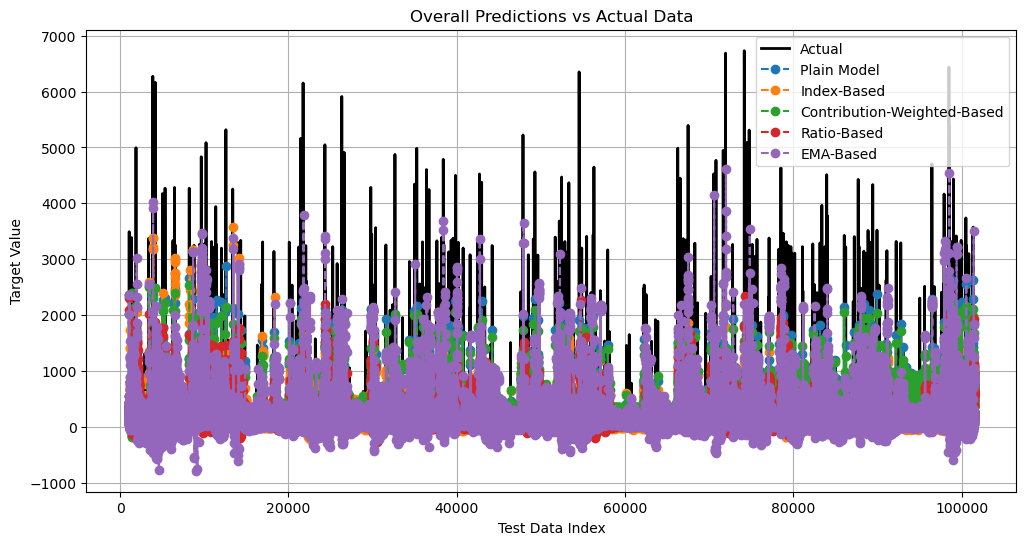

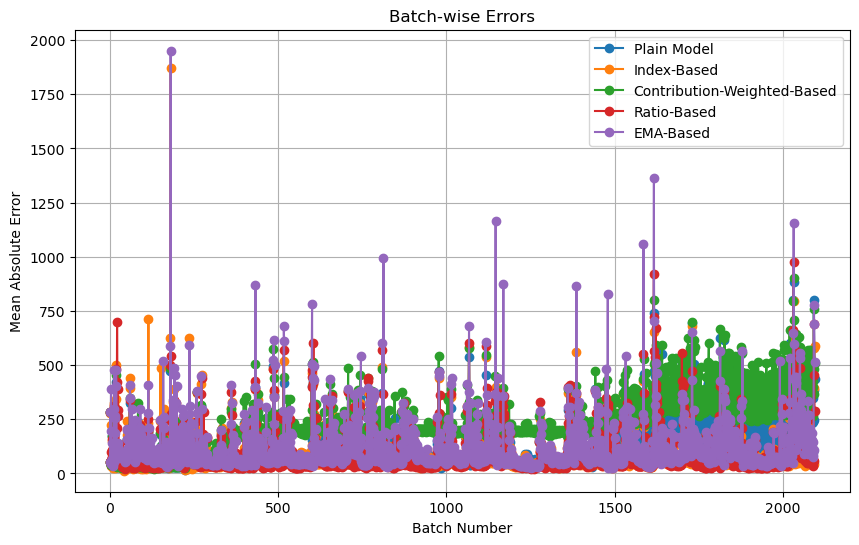

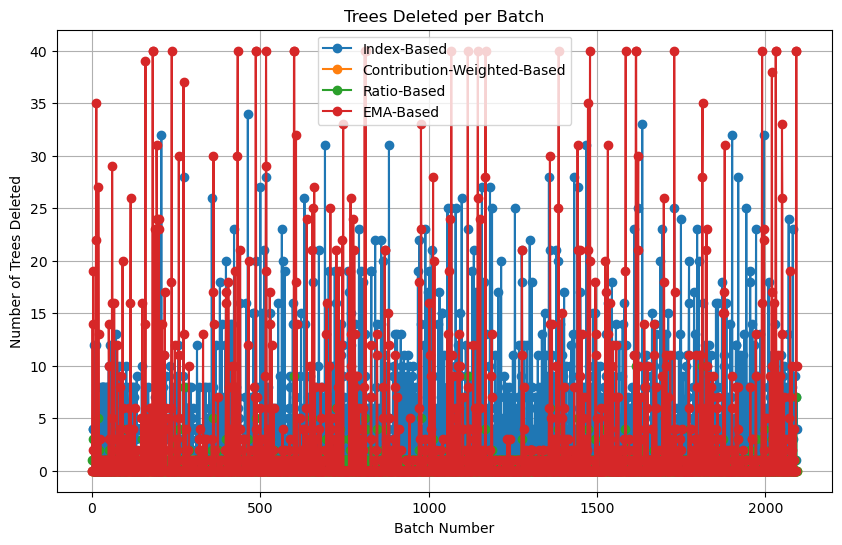


Overall Results:
                         Model  Average MAE  Total Trees Deleted
0                  Plain Model   130.644582                    0
1                  Index-Based    83.456292                 8341
2  Contribution-Weighted-Based   240.974914                   37
3                  Ratio-Based    90.135211                 1273
4                    EMA-Based   122.478981                 5703


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------------------------
# 0. Assumptions:
#    - X_test_all, y_test_all, and n_seed are already defined.
#    - y_train and X_train (used for base model training) are available.
#    - base_model is a trained GradientBoostingRegressor.
#    - ElasticGBDT class is already imported.
# ------------------------------------------------------------------------------

print("Base model trained with {} trees.".format(len(base_model.estimators_)))

# ------------------------------------------------------------------------------
# 1. Create a Plain Model Baseline (non-updated)
# ------------------------------------------------------------------------------
# We'll use the base_model as the plain model since it remains unchanged.
plain_model = base_model

# ------------------------------------------------------------------------------
# 2. Initialize ElasticGBDT Models with Different Update Methods
# ------------------------------------------------------------------------------
model_index = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=39)
model_contrib = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
model_ratio = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
model_ema = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)

models = {
    "Index-Based": model_index,
    "Contribution-Weighted-Based": model_contrib,
    "Ratio-Based": model_ratio,
    "EMA-Based": model_ema
}


models = {
    "Index-Based": model_index,
    "Contribution-Weighted-Based": model_contrib,
    "Ratio-Based": model_ratio,
    "EMA-Based": model_ema
}

# ------------------------------------------------------------------------------
# 3. Online Forecasting in Batches and Model Updates
# ------------------------------------------------------------------------------
batch_size = 48
n_remaining = len(X_test_all) - n_seed
available_batches = n_remaining // batch_size
num_batches = min(50000, available_batches)  # Process up to 5000 batches
print(f"Processing {num_batches} batches out of {available_batches} available.")

# Data structures to store predictions, errors, and trees deleted per batch
predictions_history = {name: [] for name in models}
errors_history = {name: [] for name in models}
trees_deleted_history = {name: [] for name in models}
x_indices_history = {name: [] for name in models}

# For the plain model
plain_predictions_history = []
plain_errors_history = []
plain_x_indices_history = []

# Loop over each batch
for batch in range(num_batches):
    # Define current batch indices and data
    start = n_seed + batch * batch_size
    end = start + batch_size
    X_batch = X_test_all[start:end]
    y_batch = y_test_all[start:end]
    batch_indices = np.arange(start, end)
    
    # --- Plain model prediction (no update) ---
    y_pred_plain = plain_model.predict(X_batch)
    plain_error = mean_absolute_error(y_batch, y_pred_plain)
    plain_predictions_history.append(y_pred_plain)
    plain_errors_history.append(plain_error)
    plain_x_indices_history.append(batch_indices)
    
    # --- ElasticGBDT models: prediction, update, and incremental tree building ---
    for model_name, model in models.items():
        trees_before = model.get_number_of_trees()
        
        # Predict current batch and record error
        y_pred = model.predict(X_batch)
        error = mean_absolute_error(y_batch, y_pred)
        predictions_history[model_name].append(y_pred)
        errors_history[model_name].append(error)
        x_indices_history[model_name].append(batch_indices)
        
        # Update model using its specific method with lowered multipliers:
        if model_name == "Index-Based":
            model.update_index_based(X_batch, y_batch)
        elif model_name == "Contribution-Weighted-Based":
            model.update_contribution_weighted_ratio(
                X_batch, y_batch,
                gamma_multiplier=0.1,   # lowered from 0.2
                beta_multiplier=0.2,    # lowered from 0.4
                alpha_multiplier=0.3,   # lowered from 0.7
                fixed_multiplier=0.4    # lowered from 1.1
            )
        elif model_name == "Ratio-Based":
            model.update_contribution_ratio_adapt(X_batch, y_batch, fixed_multiplier=0.6)  # lowered from 1.24
        elif model_name == "EMA-Based":
            model.update_contribution_ema(
                X_batch, y_batch,
                fixed_multiplier=0.4,   # lowered from 1.0
                moving_avg_window=5,
                ema_smoothing=0.7
            )
        
        # Calculate number of trees deleted during the update
        trees_after = model.get_number_of_trees()
        trees_deleted = max(0, trees_before - trees_after)
        trees_deleted_history[model_name].append(trees_deleted)
        
        # Compute residuals on the current batch (after update)
        residuals = y_batch - model.predict(X_batch)
        # Build incremental trees:
        # For the Index-Based model, always add 4 new trees.
        # For the others, add as many trees as were deleted.
        if model_name == "Index-Based":
            model.build_incremental_trees(X_batch, residuals, number_of_incremental_trees=4)
        else:
            if trees_deleted > 0:
                model.build_incremental_trees(X_batch, residuals, number_of_incremental_trees=trees_deleted)
    
    print(f"Completed batch {batch+1}/{num_batches}")
    
    # --- (Optional) Every 3 batches, plot the predictions for these batches concatenated together ---
    # The following block is commented out.
    """
    if (batch + 1) % 3 == 0:
        plt.figure(figsize=(12, 6))
        start_plot = n_seed + (batch - 2) * batch_size
        end_plot = n_seed + (batch + 1) * batch_size
        actual_indices = np.arange(start_plot, end_plot)
        plt.plot(actual_indices, y_test_all[start_plot:end_plot],
                 label="Actual", color="black", linewidth=2)
        
        # Plain model predictions
        plain_preds = np.concatenate(plain_predictions_history[-3:])
        plain_x = np.concatenate(plain_x_indices_history[-3:])
        plt.plot(plain_x, plain_preds, marker='o', linestyle='--', label="Plain Model")
        
        # Elastic model predictions
        for model_name in models:
            preds = np.concatenate(predictions_history[model_name][-3:])
            xs = np.concatenate(x_indices_history[model_name][-3:])
            plt.plot(xs, preds, marker='o', linestyle='--', label=model_name)
        
        plt.xlabel("Test Data Index")
        plt.ylabel("Target Value")
        plt.title(f"Predictions for Batches {batch-1} to {batch+1}")
        plt.legend()
        plt.grid(True)
        plt.show()
    """

# ------------------------------------------------------------------------------
# 4. Final Plotting after Processing All Batches
# ------------------------------------------------------------------------------

# (A) Overall Predictions vs Actual Data
plt.figure(figsize=(12, 6))
all_actual_indices = np.arange(n_seed, n_seed + num_batches * batch_size)
plt.plot(all_actual_indices, y_test_all[n_seed:n_seed + num_batches * batch_size],
         label="Actual", color="black", linewidth=2)

# Plain model overall predictions
plain_all_preds = np.concatenate(plain_predictions_history)
plain_all_x = np.concatenate(plain_x_indices_history)
plt.plot(plain_all_x, plain_all_preds, marker='o', linestyle='--', label="Plain Model")

# Elastic model overall predictions
for model_name in models:
    all_preds = np.concatenate(predictions_history[model_name])
    all_x = np.concatenate(x_indices_history[model_name])
    plt.plot(all_x, all_preds, marker='o', linestyle='--', label=model_name)

plt.xlabel("Test Data Index")
plt.ylabel("Target Value")
plt.title("Overall Predictions vs Actual Data")
plt.legend()
plt.grid(True)
plt.show()

# (B) Batch-wise Errors for each model (including the plain model)
plt.figure(figsize=(10, 6))
batches = np.arange(1, num_batches + 1)
plt.plot(batches, plain_errors_history, marker='o', linestyle='-', label="Plain Model")
for model_name, errors in errors_history.items():
    plt.plot(batches, errors, marker='o', linestyle='-', label=model_name)
plt.xlabel("Batch Number")
plt.ylabel("Mean Absolute Error")
plt.title("Batch-wise Errors")
plt.legend()
plt.grid(True)
plt.show()

# (C) Number of Trees Deleted per Batch for each ElasticGBDT Model
plt.figure(figsize=(10, 6))
for model_name, trees_deleted in trees_deleted_history.items():
    plt.plot(batches, trees_deleted, marker='o', linestyle='-', label=model_name)
plt.xlabel("Batch Number")
plt.ylabel("Number of Trees Deleted")
plt.title("Trees Deleted per Batch")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------------------------
# 5. Overall Results Table
# ------------------------------------------------------------------------------
# Create a results table summarizing the average MAE and total trees deleted for each model.
results = []
# Add plain model results (no trees deleted)
plain_avg_mae = np.mean(plain_errors_history)
results.append({
    "Model": "Plain Model",
    "Average MAE": plain_avg_mae,
    "Total Trees Deleted": 0
})

# For each ElasticGBDT model, compute average MAE and total trees deleted.
for model_name in models:
    avg_mae = np.mean(errors_history[model_name])
    total_trees_deleted = np.sum(trees_deleted_history[model_name])
    results.append({
        "Model": model_name,
        "Average MAE": avg_mae,
        "Total Trees Deleted": total_trees_deleted
    })

results_df = pd.DataFrame(results)
print("\nOverall Results:")
print(results_df)